# Chapter 7 · Project: a digital twin of rainfall seen by microwave links (simulated truth)
**Level: Expert** · ~30 min · 2D · *Applied project, part 1 of 2*

Phone networks carry data between towers on **commercial microwave links (CMLs)**. Rain
weakens their signal, so every link is an accidental rain gauge. It doesn't measure rain at a
point, though: it measures the **average rain along its path**, a few hundred metres to ten
kilometres long. FieldSense and pcpn_maps turn those path averages into rain maps by
interpolation (IDW) and show two things:
* the maps are good where links are dense
* **a link map cannot be nowcast on its own.** Its blobs are anchored to the links, so
  extrapolating their apparent motion is no better than holding the map still
  (FieldSense, `nowcasting/pysteps`).

A digital twin attacks exactly that second point. It keeps a **physical state**, the rain field
*and its motion*, that lives between the links and moves with the storm. The links only correct
it. Every piece comes from this course:

| Twin part | Here | Course chapter |
|---|---|---|
| state | log rain rate on a grid + storm velocity $(u, v)$ | Ch. 3 (state augmentation) |
| model | semi-Lagrangian advection, relaxation to a background, stochastic growth/decay | Ch. 3 (advection) |
| observation operator $H$ | average of the field along each link path | Ch. 1 ($H$), Ch. 2 |
| synchronisation | localised ensemble Kalman filter, 40 members | Ch. 3 (EnKF, localization) |
| prediction | run the ensemble forward without data | Ch. 3, Ch. 6 |

This notebook tests the twin where we **know the truth**. The rain fields and the link network
come from FieldSense's simulator (`core.simulation`). Chapter 8 runs it on real links in Gothenburg.

In [1]:
import sys, os, time; sys.path.insert(0, "..")
FIELDSENSE = os.environ.get("FIELDSENSE_DIR", os.path.expanduser("~/PycharmProjects/FieldSense"))
sys.path.insert(0, FIELDSENSE)
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML
from dtwin import viz
from core.simulation.rain_fields import Grid, StratiformField, ConvectiveField
from core.simulation.moving_fields import sequence
from core.simulation.cml_network import synthesize_network
from raintwin import RainTwin, line_idw, scores
viz.set_style()

## 1. The observation operator: what a link sees
A link from $(x_a, y_a)$ to $(x_b, y_b)$ reports

$$y_\ell = \frac{1}{|\ell|}\int_\ell R\,ds \;+\; \text{noise} \;\approx\; \sum_j H_{\ell j} R_j .$$

`raintwin.path_operator` samples 24 points along each path and spreads each point bilinearly
onto its four neighbouring cells. Each row of $H$ is then a thin line of weights that sum to one.
It's the same $H$ as in Chapter 1, but a link "selects" a whole line of cells instead of one
cell.

{'n_links': 90, 'total_path_km': 413.6680220353727, 'mean_length_km': 4.596311355948585, 'min_length_km': 0.9143435967182401, 'max_length_km': 8.09370699741598, 'median_freq_ghz': 22.959734160423807, 'frac_alpha_gt_1': 0.35555555555555557}


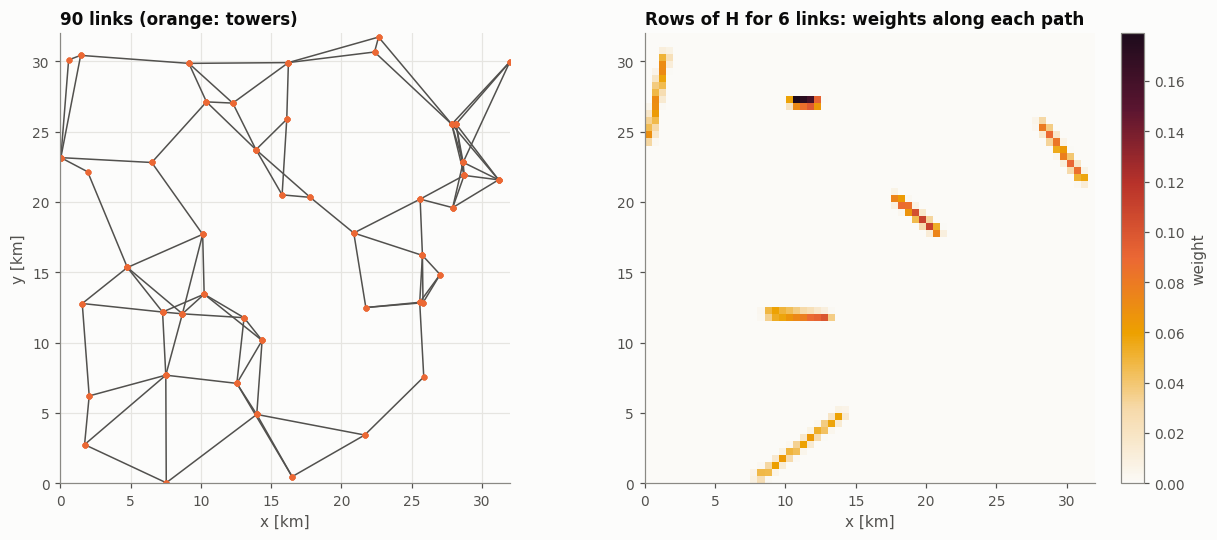

In [2]:
grid = Grid(n=64, dx_km=0.5)                      # 32 km x 32 km, 500 m cells
net = synthesize_network(grid, n_links=90)        # FieldSense's tower-and-neighbour topology
x = grid.x_km
X, Y = np.meshgrid(x, x)
links = dict(xa=net.xa, ya=net.ya, xb=net.xb, yb=net.yb)
print(net.summary())

probe = RainTwin(x, x, links)                     # only to build H here
H = probe.H
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
ax = axes[0]
for i in range(net.n_links):
    ax.plot([net.xa[i], net.xb[i]], [net.ya[i], net.yb[i]], color=viz.INK2, lw=1)
ax.plot(np.r_[net.xa, net.xb], np.r_[net.ya, net.yb], "o", color=viz.DATA, ms=3)
ax.set(aspect="equal", xlim=(0, 32), ylim=(0, 32), xlabel="x [km]", ylabel="y [km]",
       title=f"{net.n_links} links (orange: towers)")
ax = axes[1]
ax.grid(False)
im = ax.imshow(np.asarray(H[:6].sum(0)).reshape(64, 64), origin="lower", extent=(0, 32, 0, 32),
               cmap=viz.FIELD)
plt.colorbar(im, ax=ax, label="weight")
ax.set(xlabel="x [km]", title="Rows of H for 6 links: weights along each path")
plt.show()

## 2. Truth and observations
Two rain regimes from FieldSense's generators:
* **stratiform**: widespread, smooth, moving at (14, 5) km/h
* **convective**: compact intense cells, moving at (22, −8) km/h

Both evolve in the moving frame with a 60-minute decorrelation time, so the rain doesn't simply
translate: cells grow and die. One frame every 5 minutes for 6 hours. Link readings are the
path average with 10% multiplicative and 0.2 mm/h additive noise.

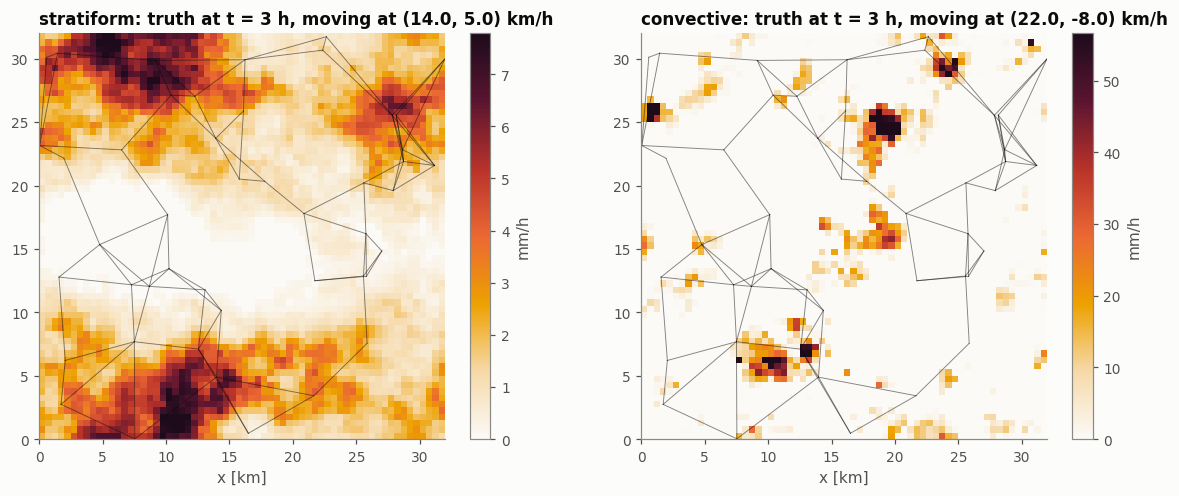

In [3]:
T, DT_H = 72, 5 / 60
rng = np.random.default_rng(0)

def make_case(model, seed=3):
    seq = sequence(model, grid, T, dt_min=5, evolve_tau_min=60, seed=seed)
    y_true = np.array([H @ f.ravel() for f in seq.frames])
    y_obs = np.clip(y_true * (1 + 0.1 * rng.standard_normal(y_true.shape))
                    + 0.2 * rng.standard_normal(y_true.shape), 0, None)
    return seq, y_obs

cases = {"stratiform": make_case(StratiformField()), "convective": make_case(ConvectiveField())}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
for ax, (name, (seq, _)) in zip(axes, cases.items()):
    ax.grid(False)
    im = ax.imshow(seq.frames[36], origin="lower", extent=(0, 32, 0, 32), cmap=viz.FIELD,
                   vmax=np.percentile(seq.frames[36], 99.5))
    for i in range(net.n_links):
        ax.plot([net.xa[i], net.xb[i]], [net.ya[i], net.yb[i]], color=viz.INK, lw=0.6, alpha=0.5)
    plt.colorbar(im, ax=ax, label="mm/h")
    ax.set(title=f"{name}: truth at t = 3 h, moving at {seq.velocity_kmh} km/h", xlabel="x [km]")
plt.show()

## 3. Running the twin
The loop is the one from Chapters 2–3:

```
initialise: members = log(IDW map of the first readings) + smooth noise; velocity ~ N(0, 15² km²/h²)
every 5 minutes:
    forecast  : advect each member with its own velocity, relax towards the background, add noise
    analysis  : EnKF update of every member's field AND velocity from the 90 link readings
```

**Why log space?** Rain is positive and highly skewed. A Kalman update on $R$ itself can produce
negative rain, and model errors in rain are multiplicative ("this cell is 30% too strong"). In
$z = \log(R + 0.1)$ both problems disappear. The link operator is nonlinear in $z$ ($R = e^z - 0.1$),
but the EnKF never needs a derivative of $H$: it only needs each member's predicted readings.

**How does it learn the velocity?** Exactly as the toy example of Chapter 3 learned κ. Members
with the right velocity predict link readings that match better, and the ensemble correlation
between "velocity" and "predicted readings" carries the correction.

In [4]:
def run_twin(seq, y_obs, n_fc_every=6, seed=1):
    tw = RainTwin(x, x, links, periodic=True, seed=seed)       # the simulator's domain is periodic
    idws = np.array([line_idw(y_obs[k], net.xa, net.ya, net.xb, net.yb, X, Y) for k in range(T)])
    tw.initialise(idws[0], vel_std=15)
    log = {"mean": [], "spread": [], "V": [], "nis": [], "fc": {}}
    for k in range(T):
        if k:
            tw.forecast(DT_H)
        st = tw.analysis(y_obs[k])
        log["mean"].append(tw.mean); log["spread"].append(tw.spread)
        log["V"].append(tw.V.copy()); log["nis"].append(st["nis"] / st["m"])
        if k >= 24 and k % n_fc_every == 0 and k + 12 < T:
            log["fc"][k] = tw.predict(12, DT_H)[0]                 # 5..60 min ahead
    for key in ("mean", "spread", "V", "nis"):
        log[key] = np.array(log[key])
    log["idw"] = idws
    return tw, log

runs = {}
for name, (seq, y_obs) in cases.items():
    t0 = time.time()
    runs[name] = run_twin(seq, y_obs)
    print(f"{name}: {T} cycles in {time.time() - t0:.0f}s")

stratiform: 72 cycles in 3s


convective: 72 cycles in 3s


## 4. Estimation: the map at "now"

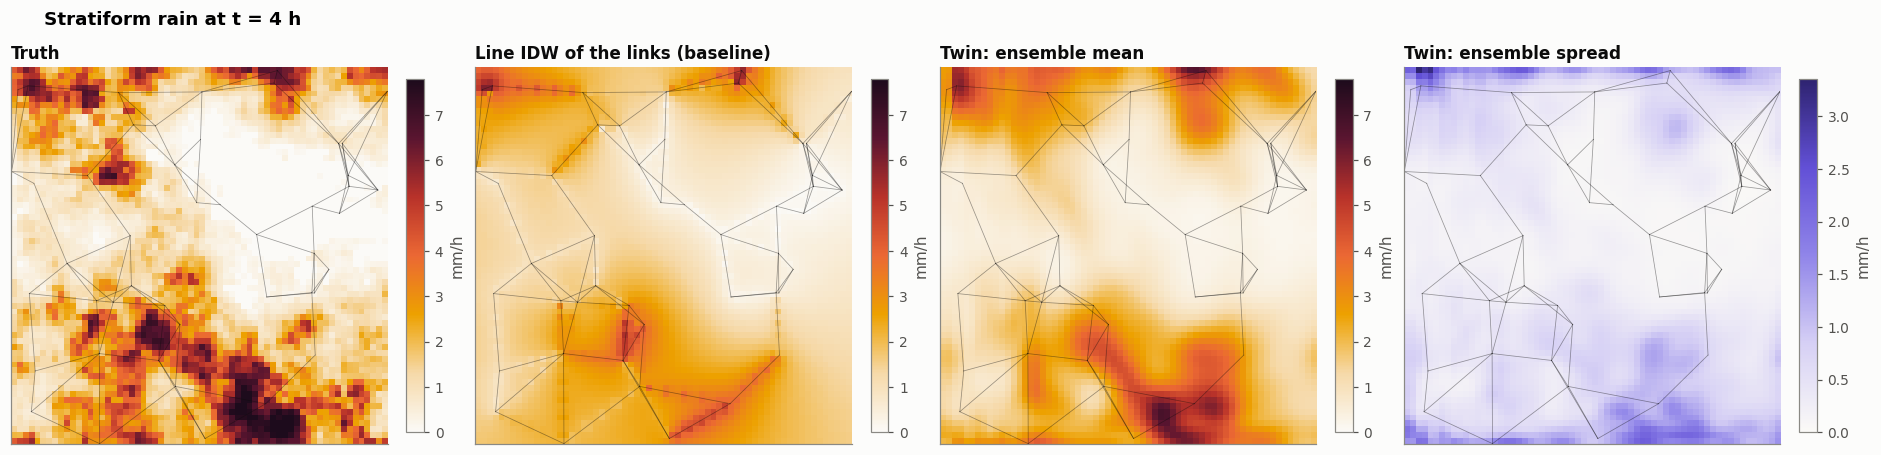

In [5]:
seq, y_obs = cases["stratiform"]
tw, log = runs["stratiform"]
k = 48
vmax = np.percentile(seq.frames[k], 99.5)
panels = [(seq.frames[k], "Truth", viz.FIELD, (0, vmax)),
          (log["idw"][k], "Line IDW of the links (baseline)", viz.FIELD, (0, vmax)),
          (log["mean"][k], "Twin: ensemble mean", viz.FIELD, (0, vmax)),
          (log["spread"][k], "Twin: ensemble spread", viz.UNCERTAINTY, (0, None))]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), constrained_layout=True)
for ax, (F, ttl, cm, (lo, hi)) in zip(axes, panels):
    ax.grid(False)
    im = ax.imshow(F, origin="lower", extent=(0, 32, 0, 32), cmap=cm, vmin=lo, vmax=hi)
    for i in range(net.n_links):
        ax.plot([net.xa[i], net.xb[i]], [net.ya[i], net.yb[i]], color=viz.INK, lw=0.5, alpha=0.4)
    plt.colorbar(im, ax=ax, label="mm/h", shrink=0.85)
    ax.set(title=ttl, xticks=[], yticks=[])
fig.suptitle(f"Stratiform rain at t = {k*5/60:.0f} h", x=0.02, ha="left", fontweight="semibold")
viz.save(fig, "07_rain_twin_maps.png")
plt.show()

The spread map shows the twin's own uncertainty: low along the links, high in the gaps.
IDW has no such map.

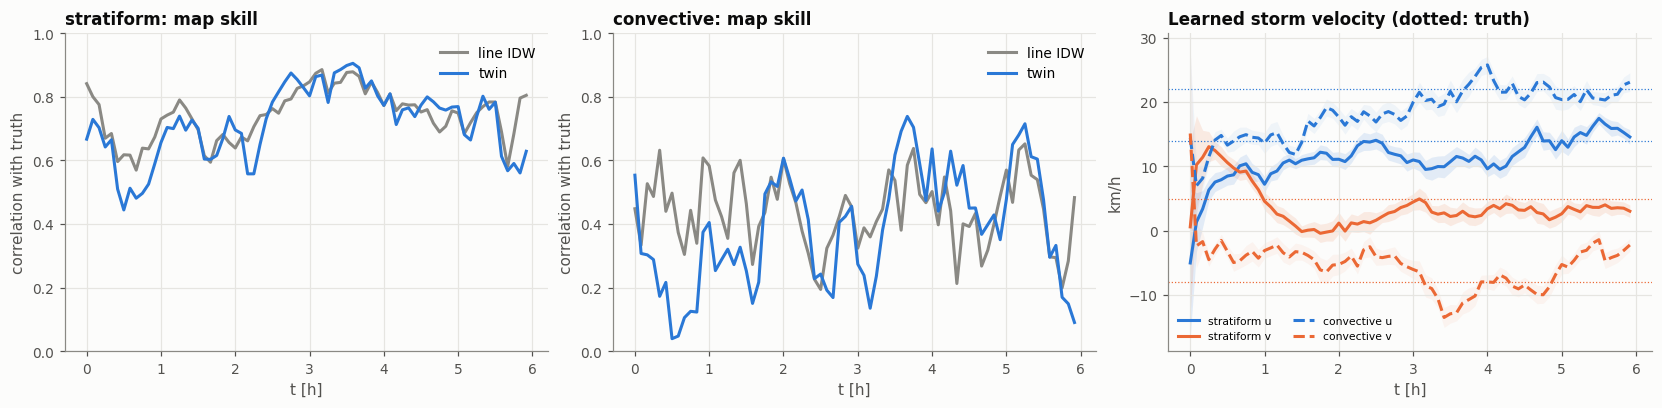

stratiform  map correlation (t > 2 h): twin 0.76   IDW 0.77   velocity [14.6  3. ] km/h (true (14.0, 5.0))
convective  map correlation (t > 2 h): twin 0.44   IDW 0.43   velocity [23.1 -2.2] km/h (true (22.0, -8.0))


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), constrained_layout=True)
tt = np.arange(T) * 5 / 60
for j, (name, (seq, _)) in enumerate(cases.items()):
    tw, log = runs[name]
    c_tw = [scores(log["mean"][k], seq.frames[k])["corr"] for k in range(T)]
    c_idw = [scores(log["idw"][k], seq.frames[k])["corr"] for k in range(T)]
    axes[j].plot(tt, c_idw, color=viz.MUTED, label="line IDW")
    axes[j].plot(tt, c_tw, color=viz.TWIN, label="twin")
    axes[j].set(xlabel="t [h]", ylabel="correlation with truth", title=f"{name}: map skill", ylim=(0, 1))
    axes[j].legend()
for j, (name, (seq, _)) in enumerate(cases.items()):
    V = runs[name][1]["V"]
    for comp, col in [(0, viz.BLUE), (1, viz.ORANGE)]:
        m, s = V[:, :, comp].mean(1), V[:, :, comp].std(1)
        axes[2].fill_between(tt, m - 2 * s, m + 2 * s, color=col, alpha=0.12 if j == 0 else 0.06, lw=0)
        axes[2].plot(tt, m, color=col, ls="-" if j == 0 else "--",
                     label=f"{name} {'u' if comp == 0 else 'v'}")
        axes[2].axhline(seq.velocity_kmh[comp], color=col, lw=0.8, ls=":")
axes[2].set(xlabel="t [h]", ylabel="km/h", title="Learned storm velocity (dotted: truth)")
axes[2].legend(fontsize=7, ncol=2)
plt.show()
for name, (seq, _) in cases.items():
    log = runs[name][1]
    ct = np.mean([scores(log["mean"][k], seq.frames[k])["corr"] for k in range(24, T)])
    ci = np.mean([scores(log["idw"][k], seq.frames[k])["corr"] for k in range(24, T)])
    print(f"{name:11s} map correlation (t > 2 h): twin {ct:.2f}   IDW {ci:.2f}   "
          f"velocity {log['V'][-1].mean(0).round(1)} km/h (true {seq.velocity_kmh})")

**Reading the result.** As a *map*, the twin is about as good as IDW: slightly worse on
smooth stratiform rain, slightly better on cells. That's honest and expected. With 90 links
over 32 km, most information about the current field is *in the links*, and IDW already uses it.
What IDW cannot do is the next section.

## 5. Prediction: nowcasting 5–60 minutes ahead
Every 30 minutes the twin forecasts the next hour with no data. We compare against:
* **IDW persistence**: the current link map held still, the baseline FieldSense found
  impossible to beat by extrapolating link maps
* **Lagrangian persistence of the truth**: the *true* field moved at the *true* velocity, the
  ceiling for any method that only moves rain around

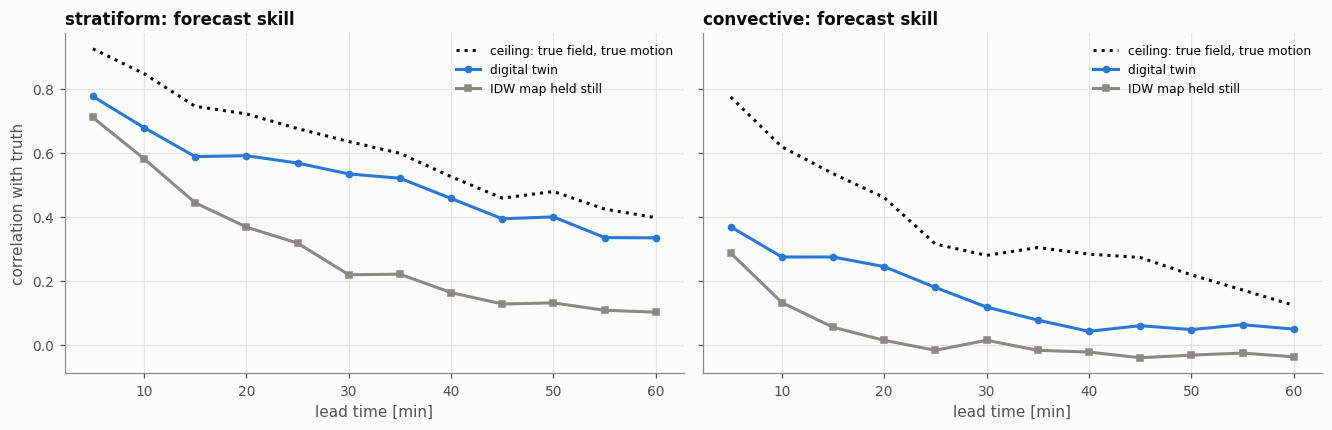

stratiform  30 min: twin 0.53  IDW persistence 0.22  ceiling 0.64   |  60 min: twin 0.33  IDW 0.10
convective  30 min: twin 0.12  IDW persistence 0.01  ceiling 0.28   |  60 min: twin 0.05  IDW -0.04


In [7]:
hz = np.arange(1, 13)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True, sharey=True)
summary = {}
for ax, (name, (seq, _)) in zip(axes, cases.items()):
    log = runs[name][1]
    sk = {"twin": [], "IDW persistence": [], "ceiling": []}
    for h in hz:
        a, b, c = [], [], []
        for k, P in log["fc"].items():
            a.append(scores(P[h - 1], seq.frames[k + h])["corr"])
            b.append(scores(log["idw"][k], seq.frames[k + h])["corr"])
            c.append(scores(seq.lagrangian_persistence(k, h), seq.frames[k + h])["corr"])
        sk["twin"].append(np.mean(a)); sk["IDW persistence"].append(np.mean(b)); sk["ceiling"].append(np.mean(c))
    summary[name] = sk
    ax.plot(hz * 5, sk["ceiling"], color=viz.INK, ls=":", label="ceiling: true field, true motion")
    ax.plot(hz * 5, sk["twin"], "o-", color=viz.TWIN, ms=4, label="digital twin")
    ax.plot(hz * 5, sk["IDW persistence"], "s-", color=viz.MUTED, ms=4, label="IDW map held still")
    ax.set(xlabel="lead time [min]", title=f"{name}: forecast skill")
    ax.legend(fontsize=8)
axes[0].set_ylabel("correlation with truth")
viz.save(fig, "07_rain_twin_nowcast.png")
plt.show()
for name, sk in summary.items():
    print(f"{name:11s} 30 min: twin {sk['twin'][5]:.2f}  IDW persistence {sk['IDW persistence'][5]:.2f}  "
          f"ceiling {sk['ceiling'][5]:.2f}   |  60 min: twin {sk['twin'][11]:.2f}  IDW {sk['IDW persistence'][11]:.2f}")

**This is what the twin adds.** Because its state carries the motion, its forecast follows the
storm, while the link map stays anchored to the links. For stratiform rain the twin recovers
most of the gap to the ceiling at 30 minutes. For convective cells everything decays fast
(cells live about an hour), but the twin still keeps a clear lead at 15–30 minutes.

## 6. Is the twin honest about its uncertainty?
As in Chapters 2–3: NIS per link should be about 1 if the spread matches the actual error.

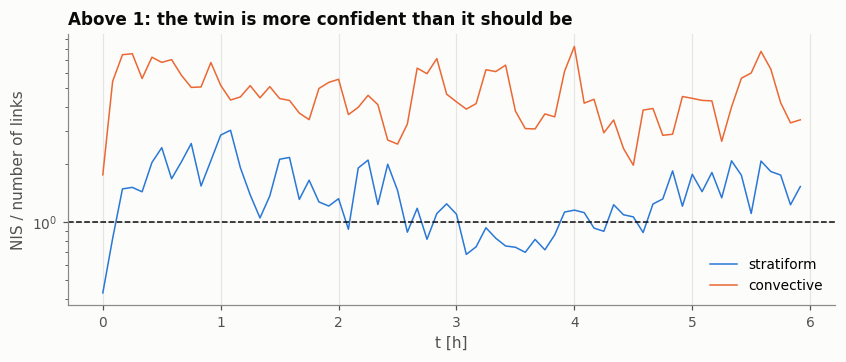

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.2))
for j, name in enumerate(cases):
    ax.plot(tt, runs[name][1]["nis"], color=viz.SERIES[j], lw=1, label=name)
ax.axhline(1, color=viz.INK, ls="--", lw=1)
ax.set(xlabel="t [h]", ylabel="NIS / number of links", yscale="log",
       title="Above 1: the twin is more confident than it should be")
ax.legend()
plt.show()

NIS sits at about 1.4 for stratiform rain (nearly honest) and about 4 for convective rain
(over-confident). A smooth, 3-cell-wide model error can't represent cells popping up between
links. Better model error for convection is the first research direction listed below.

In [9]:
seq, _ = cases["convective"]
log = runs["convective"][1]
sel = np.arange(0, T, 2)
vm = np.percentile(seq.frames, 99.5)
anim = viz.animate_2d([seq.frames[sel], log["idw"][sel], log["mean"][sel]], sel * 5 / 60,
                      ["Truth (convective)", "Line IDW", "Digital twin"],
                      vlims=[(0, vm)] * 3, L=32.0, size=3.3, interval=140)
HTML(anim.to_jshtml())

## Summary
* A link is a **line-integral sensor**. As a twin observation operator it's just a sparse
  matrix $H$.
* An EnKF in log-rain space with the **storm velocity in the state** learns the motion from the
  links alone.
* **Estimation:** about as good as IDW. **Prediction:** far better than the link map held still,
  because the twin's state moves with the storm.
* Known weaknesses: over-confidence for convective rain, and the forecast decays toward the
  background because there is no growth model.

**Research directions (for a FieldSense project)**
1. Convective model error: random cell birth instead of smooth multiplicative noise.
2. A spatially varying motion field (a coarse velocity grid in the state) instead of one vector.
3. Add PWS and gauges as point observations: the same `path_operator` with $x_a = x_b$.
4. Assimilate radar too, and let the links correct it, which is the merging problem as a twin.

**Next: Chapter 8** runs the same twin on 364 real links in Gothenburg, scored against rain
gauges that the twin never sees.